# EDA 07: cách chọn điểm neo của stay point (`li` so với `h1_keep`)

Tiếp nối `06_staypoint_thresholds.ipynb` (mục 14–17 kiểm chứng D = 200 m, T = 30 phút bằng nhãn phương tiện). Notebook này chọn **cách đặt điểm neo** trong thuật toán stay point; việc xử lý khoảng trống (gap-stay) ở `08_gap_stay.ipynb`.

| Mục | Câu hỏi |
|---|---|
| 18 | Thuật toán mới `h1_keep` khác Li thế nào, tổng quan thay đổi bao nhiêu? |
| 19 | Lỗi tách stay có giảm không, `h1_keep` đã làm gì với từng stay của Li? |
| 20 | Có nhận nhầm thêm trên đoạn có nhãn không? |
| 21 | Địa điểm đứng đầu và từng user có bị ảnh hưởng không, chốt thuật toán nào? |

**Cách chạy.** Cần `data/processed/clean` và `data/interim/labels`. Từng mục tự import nên có thể chạy riêng. Mục 18 tính nặng: lưu kết quả từng user vào `data/interim/eda_stay_anchor/`, lần sau đọc lại trong vài giây; đổi code `src/eda/stay_anchor.py` thì xoá thư mục này. Chỉ muốn đọc kết luận: xem các ô markdown, không cần chạy.

## 18. Thuật toán mới `h1_keep` so với Li

**Hai thuật toán** (cùng D = 200 m, T = 30 phút, cùng cách gộp file và ngắt ở khoảng trống > 24 giờ như `src/stays/detect.py`):

| | `li` (đang dùng) | `h1_keep` (đề xuất) |
|---|---|---|
| Chọn neo | điểm **sớm nhất** đủ T | chạy Li trước, rồi dời neo vào **giữa** stay (điểm trung vị theo thời gian) |
| Mở rộng | chỉ **về sau** neo | **cả hai phía** neo |
| Khi nào nhận stay mới | – | chỉ khi **không ngắn hơn** stay của Li; ngắn hơn thì giữ stay của Li |
| Tham số thêm | – | không có |

Trung vị lấy theo **thời gian** (trọng số w_k = min(t[k+1] − t[k], 30 phút)), không theo số điểm. Hình dưới là quỹ đạo giả lập để thấy cách làm.

Đã thử thêm hai cách chọn neo theo "độ mạnh" (`h2`: neo lưới 1 phút; `h3`: neo ở chỗ dày điểm nhất) nhưng đã loại (ở lần chạy trước) vì làm đổi địa điểm đứng đầu ở nhiều user và nhận nhầm tăng quá ngưỡng; code đã bỏ.

**Kế hoạch đo** (mục 18–21):

| # | Câu hỏi | Trình bày |
|---|---|---|
| 18.1 | Tổng quan thay đổi bao nhiêu? | bảng 1, hình phân bố thời lượng |
| 19.1 | Lỗi tách stay có giảm không? | bảng 2 |
| 19.2 | `h1_keep` đã làm gì với từng stay của Li? | bảng 3, ví dụ thật |
| 20 | Có nhận nhầm thêm không (69 user có nhãn)? | bảng 4 |
| 21.1 | Hai địa điểm đứng đầu có đổi không? | bảng 5 |
| 21.2 | Có user nào bị ảnh hưởng xấu không? | bảng 6, hình theo user |
| 21.3 | Chốt | bảng điểm |

**Cách chạy.** `USERS = None` chạy toàn bộ nhóm dev (`split.dev_users()`, D17). Lần đầu: mục 18 khoảng 30–60 phút (nếu chưa có cache `*_full.pkl`), `run_compare` vài phút. Kết quả từng user lưu ở `data/interim/eda_stay_anchor/`; đổi code `stay_anchor.py` thì xoá thư mục này.

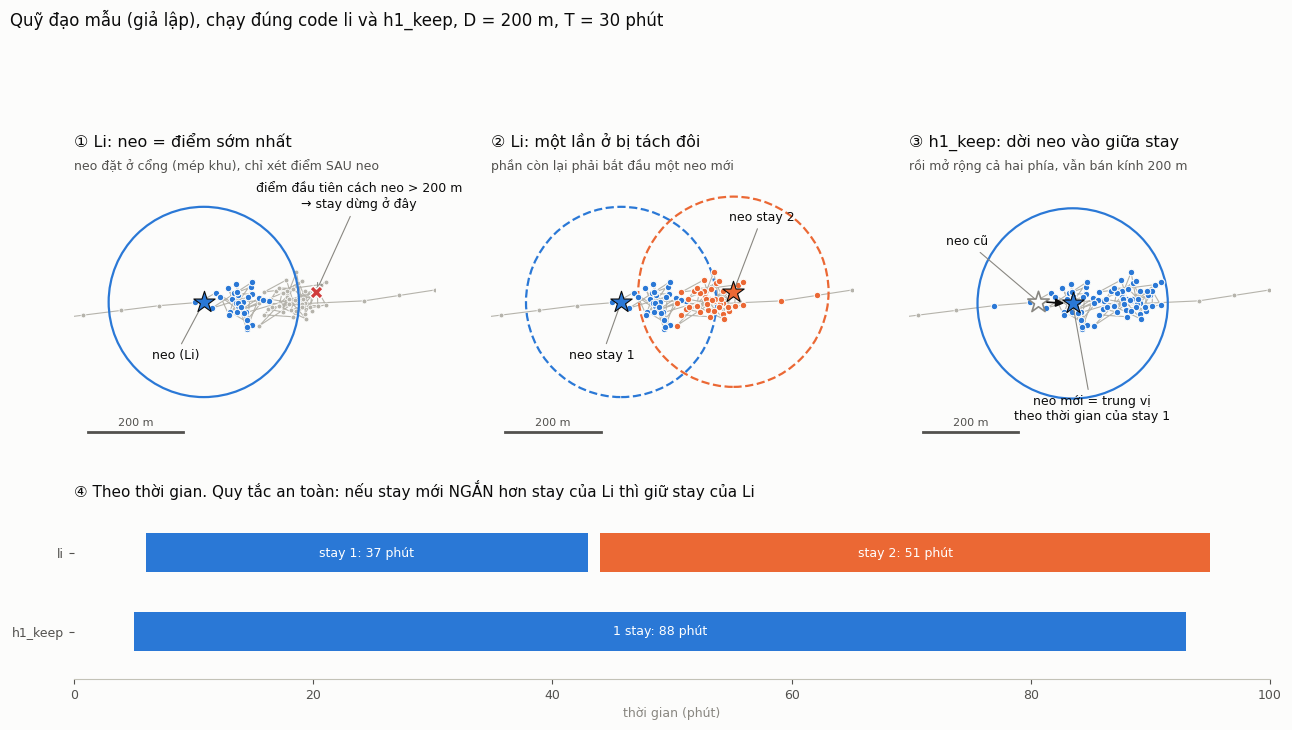

In [16]:
# chạy được ngay cả khi chưa chạy các mục trước
import importlib
from pathlib import Path
import sys
import numpy as np
import pandas as pd
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
from preprocess import interim
from eda import stay_anchor as sa
from eda import stay_anchor_plots as sp
from eda import split
importlib.reload(sa); importlib.reload(sp)
sp.demo_li_vs_h1();

### 18.1 Tổng quan

`run_users` cho chỉ số tổng hợp từng user (dùng lại kết quả đã lưu); `run_compare` lưu thêm từng stay, số đếm cách `h1_keep` xử lý stay của Li, và hai địa điểm đầu kèm giờ đêm / giờ hành chính.

122 user đã có kết quả, 0 user cần tính, 15 tiến trình
122 user đã có kết quả, 0 user cần tính, 15 tiến trình
Bảng 1. Tổng quan, 122 user


,li,h1_keep,chênh lệch,chênh lệch (%)
số stay,12312.0,11742.0,-570.0,-4.6
tổng giờ stay,56655.9,57224.2,568.3,1.0
giờ có GPS,5460.1,5754.9,294.8,5.4
giờ khoảng trống (gap),51195.7,51469.3,273.5,0.5
"thời lượng stay, trung vị (giờ)",1.8,2.0,0.2,14.1
"thời lượng stay, p90 (giờ)",12.9,13.1,0.2,1.6
"bán kính 95% điểm, trung vị (m)",120.5,150.5,30.0,24.9


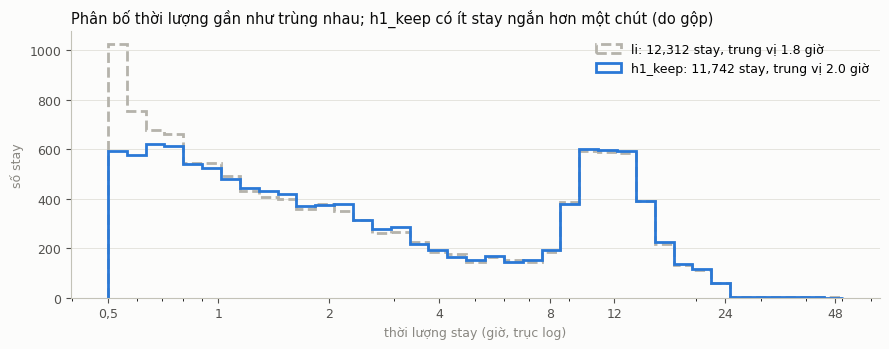

In [17]:
USERS = None      # ví dụ ["000", "001", "002"] để chạy thử nhanh

users = split.dev_users()
if USERS:
    users = [u for u in users if u in set(USERS)]
S18, P18 = sa.run_users(users, sa.CMP)
CS, CH, CPL = sa.run_compare(users)

def so_sanh(rows):
    """rows: {tên chỉ số: (giá trị li, giá trị h1_keep)} → bảng li │ h1_keep │ chênh lệch │ chênh lệch %."""
    b = pd.DataFrame(rows, index=["li", "h1_keep"]).T
    b["chênh lệch"] = b["h1_keep"] - b["li"]
    b["chênh lệch (%)"] = 100 * b["chênh lệch"] / b["li"].where(b["li"] != 0)
    return b

tong = S18.groupby("variant")[["n_stays", "hours", "gps_hours", "gap_hours"]].sum()
dur = CS.groupby("variant")["dur_h"]
rad = CS.groupby("variant")["rad95_m"].median()
bang1 = so_sanh({
    "số stay": tong["n_stays"],
    "tổng giờ stay": tong["hours"],
    "  giờ có GPS": tong["gps_hours"],
    "  giờ khoảng trống (gap)": tong["gap_hours"],
    "thời lượng stay, trung vị (giờ)": dur.median(),
    "thời lượng stay, p90 (giờ)": dur.quantile(0.9),
    "bán kính 95% điểm, trung vị (m)": rad,
})
print(f"Bảng 1. Tổng quan, {S18['user'].nunique()} user")
display(bang1.round(1))
sp.duration_dist(CS);

## 19. Lỗi tách stay và cách `h1_keep` xử lý

**Stay bị tách** (`n_split`): hai stay liền nhau có tâm cách < 200 m và nghỉ < 10 phút, tức một lần ở bị cắt đôi. Đây là lỗi `h1_keep` cần sửa.

**Cách `h1_keep` xử lý mỗi stay của Li:**
- *dời neo*: stay mới (neo ở giữa, mở hai phía) không ngắn hơn, nên dùng stay mới;
- *giữ nguyên*: stay mới ngắn hơn, nên giữ stay của Li;
- *được gộp*: stay của Li đã bị stay trước (đã mở rộng) phủ hết, nên gộp vào stay trước.

In [18]:
ns = S18.pivot(index="user", columns="variant", values="n_split")
nst = S18.pivot(index="user", columns="variant", values="n_stays")
bang2 = so_sanh({
    "số cặp stay bị tách": ns.sum(),
    "stay bị tách / 100 stay": 100 * ns.sum() / nst.sum(),
    "số user có ít nhất 1 cặp bị tách": (ns > 0).sum(),
})
print("Bảng 2. Stay bị tách")
display(bang2.round(1))
d = ns["h1_keep"] - ns["li"]
print(f"Theo user: {100 * (d < 0).mean():.0f}% user giảm, {100 * (d == 0).mean():.0f}% không đổi, "
      f"{100 * (d > 0).mean():.0f}% tăng số cặp bị tách")

h = CH[["n_li", "moved", "kept", "absorbed"]].sum()
bang3 = pd.DataFrame({"số stay của Li": [h["moved"], h["kept"], h["absorbed"]]},
                     index=["dời neo (dùng stay mới)", "giữ nguyên (stay mới ngắn hơn)", "được gộp vào stay trước"])
bang3["%"] = 100 * bang3["số stay của Li"] / h["n_li"]
bang3.loc["tổng"] = [h["n_li"], 100.0]
print("Bảng 3. h1_keep đã làm gì với từng stay của Li")
display(bang3.round(1))

Bảng 2. Stay bị tách


,li,h1_keep,chênh lệch,chênh lệch (%)
số cặp stay bị tách,1066.0,587.0,-479.0,-44.9
stay bị tách / 100 stay,8.7,5.0,-3.7,-42.3
số user có ít nhất 1 cặp bị tách,77.0,69.0,-8.0,-10.4


Theo user: 52% user giảm, 45% không đổi, 2% tăng số cặp bị tách
Bảng 3. h1_keep đã làm gì với từng stay của Li


,số stay của Li,%
dời neo (dùng stay mới),6704.0,54.5
giữ nguyên (stay mới ngắn hơn),5038.0,40.9
được gộp vào stay trước,570.0,4.6
tổng,12312.0,100.0


### 19.2 Ví dụ thật

Lấy user có nhiều stay được gộp nhất, chọn một stay của `h1_keep` (dài ≤ 12 giờ) chứa trọn nhiều stay của Li nhất. Hình vẽ giống hình giả lập ở mục 18:
- **trái (Li):** mỗi màu là một stay của Li; ★ là neo (điểm đầu của stay), vòng nét đứt là 200 m quanh neo; ✕ là điểm đầu tiên cách neo hơn 200 m, nơi Li cắt stay.
- **phải (h1_keep):** ★ xanh là neo mới (trung vị theo thời gian của stay Li đầu tiên), vòng liền là 200 m quanh neo mới.
- **dưới:** cùng khoảng đó theo thời gian; ✕ là lúc Li cắt.

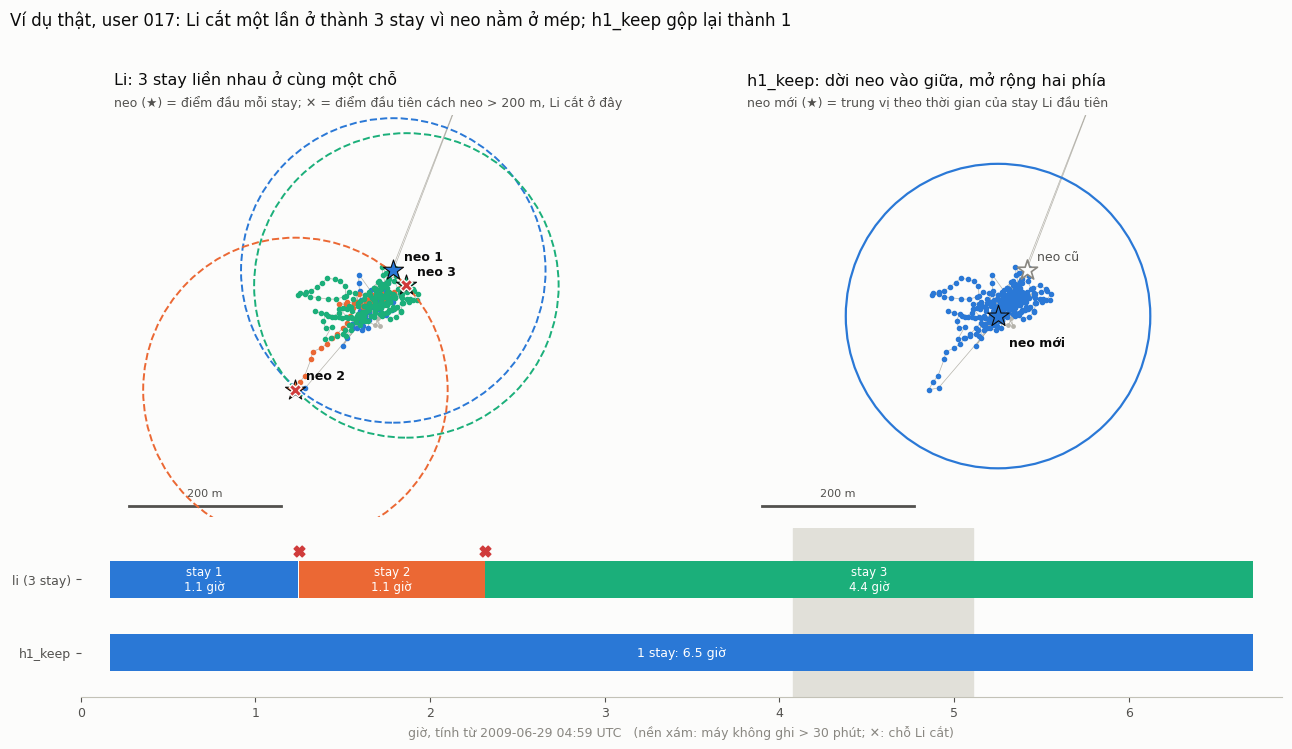

In [19]:
vi_du = CH.sort_values("absorbed", ascending=False)["user"].iloc[0]
ex = sa.merge_example(vi_du, CS)
if ex is not None:
    sp.merge_example_plot(ex);

## 20. Nhận nhầm trên đoạn có nhãn

Giống mục 15 của notebook 06 nhưng cho cả hai thuật toán: chạy chỉ trên các đoạn có nhãn **đang di chuyển** (cắt thêm ở khoảng trống > 30 phút), mọi stay tìm được là stay giả. Tách riêng `walk` (thường là đi loanh quanh trong một khu) và các loại xe (nhận nhầm thật). Hàng `li` phải khớp mục 15 của notebook 06 ở D = 200 m, T = 30 phút; không khớp thì có lỗi.

In [20]:
from eda import stay_scan as ss
label_users = ss.labeled_users()
F19 = sa.run_labels(label_users, sa.CMP)
F19 = F19[F19["variant"].isin(sa.CMP)]
XE = {"bus", "car", "taxi", "train", "subway", "airplane", "boat", "motorcycle"}
F19["nhóm"] = np.where(F19["mode"] == "walk", "walk", np.where(F19["mode"].isin(XE), "xe", "khác"))
g = F19.groupby(["variant", "nhóm"])[["hours", "false_hours"]].sum()
pct = (100 * g["false_hours"] / g["hours"]).unstack("nhóm").reindex(columns=["walk", "xe", "khác"])
t19 = F19.groupby("variant")[["hours", "false_hours", "n_false"]].sum()
bang4 = so_sanh({
    "tổng (%)": 100 * t19["false_hours"] / t19["hours"],
    "  walk (%)": pct["walk"],
    "  xe (%)": pct["xe"],
    "  khác (%)": pct["khác"],
    "stay giả / 100 giờ di chuyển": 100 * t19["n_false"] / t19["hours"],
})
bang4 = bang4.drop(columns="chênh lệch (%)").rename(columns={"chênh lệch": "chênh lệch (điểm %)"})
print(f"Bảng 4. % thời gian di chuyển có nhãn bị nhận là stay, {len(label_users)} user")
display(bang4.round(2))

[10/47] user 069 (0 giây)
[20/47] user 097 (0 giây)
[30/47] user 111 (1 giây)
[40/47] user 138 (1 giây)
[47/47] user 179 (1 giây)
Bảng 4. % thời gian di chuyển có nhãn bị nhận là stay, 47 user


,li,h1_keep,chênh lệch (điểm %)
tổng (%),10.08,10.74,0.66
walk (%),27.31,29.29,1.98
xe (%),2.31,2.42,0.11
khác (%),5.78,5.95,0.17
stay giả / 100 giờ di chuyển,12.78,11.97,-0.81


## 21. Địa điểm đứng đầu, theo từng user, và chốt

### 21.1 Hai địa điểm đứng đầu

Gom stay bằng `cluster_v1` (200 m, stay dài nhất làm tâm), so địa điểm thứ 1 và thứ 2 (theo tổng giờ) của `h1_keep` với của Li. Giờ đêm (0–6h) và giờ hành chính (thứ 2–6, 9–17h) tính theo giờ địa phương, vì bước home/office sẽ dùng chúng.

In [21]:
A = CPL[CPL["variant"] == "li"].set_index(["user", "rank"])
B = CPL[CPL["variant"] == "h1_keep"].set_index(["user", "rank"])
A, B = A.align(B, join="inner", axis=0)
lech = pd.Series(sa.haversine_m(A["lat"].to_numpy(), A["lon"].to_numpy(), B["lat"].to_numpy(), B["lon"].to_numpy()), index=A.index)
rows = []
for r in (1, 2):
    m = lech.xs(r, level="rank")
    a, b = A.xs(r, level="rank"), B.xs(r, level="rank")
    pchg = lambda c: (100 * (b[c] - a[c]) / a[c].where(a[c] > 0)).median()
    rows.append({"địa điểm": r, "số user": len(m), "tâm lệch, trung vị (m)": m.median(), "tâm lệch, p90 (m)": m.quantile(0.9),
                 "% user lệch > 100 m": 100 * (m > 100).mean(), "đổi tổng giờ, trung vị (%)": pchg("hours"),
                 "đổi giờ đêm, trung vị (%)": pchg("night_hours"), "đổi giờ hành chính, trung vị (%)": pchg("office_hours")})
bang5 = pd.DataFrame(rows).set_index("địa điểm").T
print("Bảng 5. Hai địa điểm đứng đầu: h1_keep so với li")
display(bang5.round(1))

Bảng 5. Hai địa điểm đứng đầu: h1_keep so với li


địa điểm,1,2
số user,114.0,110.0
"tâm lệch, trung vị (m)",0.7,0.0
"tâm lệch, p90 (m)",57.0,118.8
% user lệch > 100 m,5.3,10.9
"đổi tổng giờ, trung vị (%)",0.2,0.1
"đổi giờ đêm, trung vị (%)",0.0,0.0
"đổi giờ hành chính, trung vị (%)",0.1,0.1


### 21.2 Theo từng user

Tổng có thể che user bị ảnh hưởng nhiều. Bảng 6 cho phân bố thay đổi theo user; danh sách dưới là 10 user đổi tổng giờ stay nhiều nhất (nên mở bản đồ của họ nếu cần kiểm tra).

Bảng 6. Phân bố thay đổi theo user (xấu nhất: tăng số stay / giảm giờ / tăng cặp tách / lệch xa nhất)


,p10,trung vị,p90,xấu nhất
đổi số stay (%),-11.5,-3.0,0.0,0.0
đổi tổng giờ stay (%),0.0,0.7,3.8,-12.3
đổi số cặp bị tách,-12.8,-1.0,0.0,1.0
tâm địa điểm 1 lệch (m),0.0,0.7,57.0,2255.8


10 user đổi tổng giờ stay nhiều nhất


,đổi số stay (%),đổi tổng giờ stay (%),đổi số cặp bị tách,tâm địa điểm 1 lệch (m)
user,,,,
019,-6.2,22.2,-2,11.0
138,0.0,13.8,0,20.5
067,-6.3,12.5,-7,102.3
033,-18.0,-12.3,-8,6.9
058,-12.5,-11.9,-2,0.0
121,-20.0,11.4,-1,37.2
156,0.0,8.1,0,0.0
124,0.0,6.0,0,94.7
052,-11.3,5.5,-23,0.0


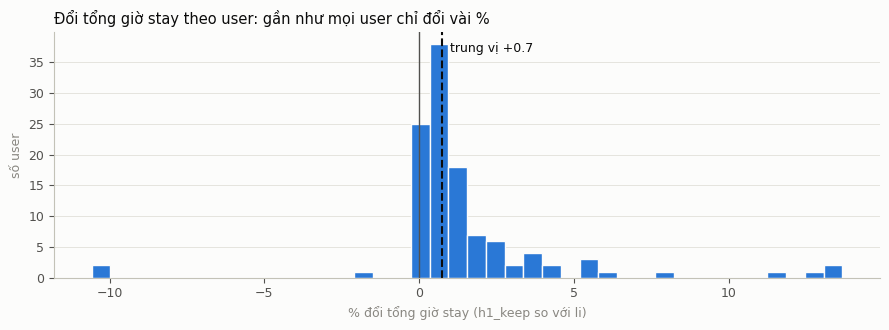

In [22]:
X = S18.pivot(index="user", columns="variant")
chg = pd.DataFrame({
    "đổi số stay (%)": 100 * (X[("n_stays", "h1_keep")] / X[("n_stays", "li")] - 1),
    "đổi tổng giờ stay (%)": 100 * (X[("hours", "h1_keep")] / X[("hours", "li")] - 1),
    "đổi số cặp bị tách": X[("n_split", "h1_keep")] - X[("n_split", "li")],
    "tâm địa điểm 1 lệch (m)": lech.xs(1, level="rank"),
})
bang6 = chg.quantile([0.1, 0.5, 0.9]).T
bang6.columns = ["p10", "trung vị", "p90"]
bang6["xấu nhất"] = [chg.iloc[:, 0].max(), chg.iloc[:, 1].min(), chg.iloc[:, 2].max(), chg.iloc[:, 3].max()]
print("Bảng 6. Phân bố thay đổi theo user (xấu nhất: tăng số stay / giảm giờ / tăng cặp tách / lệch xa nhất)")
display(bang6.round(1))
print("10 user đổi tổng giờ stay nhiều nhất")
display(chg.reindex(chg["đổi tổng giờ stay (%)"].abs().sort_values(ascending=False).index).head(10).round(1))
sp.user_change_hist(chg["đổi tổng giờ stay (%)"], "Đổi tổng giờ stay theo user: gần như mọi user chỉ đổi vài %",
                    "% đổi tổng giờ stay (h1_keep so với li)");

### 21.3 Chốt

Ba tiêu chí, mỗi tiêu chí là một câu hỏi:
1. **Một lần ở có còn bị cắt đôi không?** Stay bị tách / 100 stay (bảng 2) phải giảm ít nhất 20%.
2. **Có nhận nhầm lúc đang đi là ở yên không?** % thời gian di chuyển có nhãn bị nhận là stay (bảng 4) không tăng quá 1 điểm %.
3. **Nơi ở nhiều nhất có bị đổi chỗ không?** Ít nhất 90% user giữ nguyên địa điểm 1, tức tâm lệch < 100 m (bảng 5).

Hình và các dòng tóm tắt dưới đều tính từ bảng 1–6 ở trên.

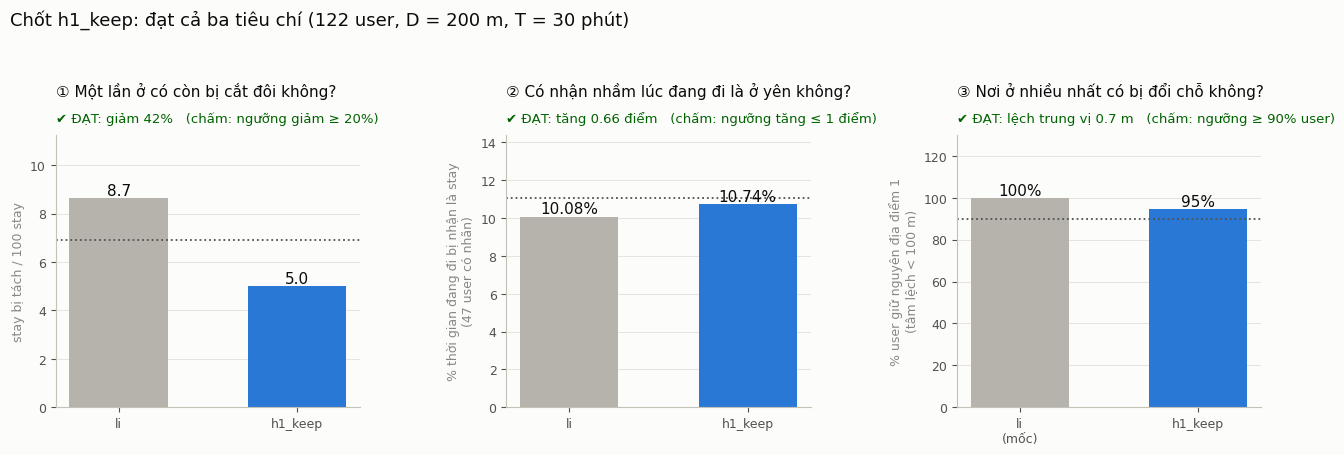

In [23]:
r95 = CS.groupby("variant")["rad95_m"].median()
m = {"n_users": S18["user"].nunique(), "n_label_users": len(label_users),
     "split_li": bang2.at["stay bị tách / 100 stay", "li"], "split_h1": bang2.at["stay bị tách / 100 stay", "h1_keep"],
     "pairs_li": int(ns["li"].sum()), "pairs_h1": int(ns["h1_keep"].sum()),
     "false_li": bang4.at["tổng (%)", "li"], "false_h1": bang4.at["tổng (%)", "h1_keep"],
     "car_li": bang4.at["  xe (%)", "li"], "car_h1": bang4.at["  xe (%)", "h1_keep"],
     "shift1": bang5.at["% user lệch > 100 m", 1], "shift2": bang5.at["% user lệch > 100 m", 2],
     "shift1_med": bang5.at["tâm lệch, trung vị (m)", 1], "shift2_med": bang5.at["tâm lệch, trung vị (m)", 2],
     "only_h1": S18.loc[S18["variant"] == "h1_keep", "hours_only_variant"].sum(),
     "only_li": S18.loc[S18["variant"] == "h1_keep", "hours_only_li"].sum(),
     "hours_li": tong.at["li", "hours"], "hours_h1": tong.at["h1_keep", "hours"],
     "rad_li": r95["li"], "rad_h1": r95["h1_keep"],
     "n_li": int(tong.at["li", "n_stays"]), "n_h1": int(tong.at["h1_keep", "n_stays"]),
     "absorbed": int(h["absorbed"]), "kept_pct": 100 * h["kept"] / h["n_li"]}
sp.scorecard(m);

In [24]:
ok = [m["split_h1"] <= 0.8 * m["split_li"], m["false_h1"] - m["false_li"] <= 1, 100 - m["shift1"] >= 90]
print(f"{m['n_users']} user. Đạt {sum(ok)}/3 tiêu chí.")
print(f"1. Stay bị tách / 100 stay: {m['split_li']:.1f} → {m['split_h1']:.1f} (giảm {100 * (1 - m['split_h1'] / m['split_li']):.0f}%; "
      f"số cặp {m['pairs_li']:,} → {m['pairs_h1']:,})  {'ĐẠT' if ok[0] else 'CHƯA ĐẠT'}")
print(f"2. Nhận nhầm tổng: {m['false_li']:.2f}% → {m['false_h1']:.2f}% ({m['false_h1'] - m['false_li']:+.2f} điểm), "
      f"xe {m['car_li']:.2f}% → {m['car_h1']:.2f}%  {'ĐẠT' if ok[1] else 'CHƯA ĐẠT'}")
print(f"3. User giữ nguyên địa điểm 1: {100 - m['shift1']:.1f}% (địa điểm 2: {100 - m['shift2']:.1f}%), "
      f"tâm lệch trung vị {m['shift1_med']:.1f} m  {'ĐẠT' if ok[2] else 'CHƯA ĐẠT'}")
print(f"Khác: tổng giờ stay {m['hours_li']:,.0f} → {m['hours_h1']:,.0f} ({100 * (m['hours_h1'] / m['hours_li'] - 1):+.1f}%), "
      f"thêm {m['only_h1']:,.0f} giờ Li bỏ sót, bỏ {m['only_li']:,.0f} giờ; số stay {m['n_li']:,} → {m['n_h1']:,}; "
      f"bán kính 95% trung vị {m['rad_li']:.0f} → {m['rad_h1']:.0f} m")

122 user. Đạt 3/3 tiêu chí.
1. Stay bị tách / 100 stay: 8.7 → 5.0 (giảm 42%; số cặp 1,066 → 587)  ĐẠT
2. Nhận nhầm tổng: 10.08% → 10.74% (+0.66 điểm), xe 2.31% → 2.42%  ĐẠT
3. User giữ nguyên địa điểm 1: 94.7% (địa điểm 2: 89.1%), tâm lệch trung vị 0.7 m  ĐẠT
Khác: tổng giờ stay 56,656 → 57,224 (+1.0%), thêm 650 giờ Li bỏ sót, bỏ 82 giờ; số stay 12,312 → 11,742; bán kính 95% trung vị 120 → 150 m


**Đề xuất:** nếu đạt cả ba tiêu chí thì dùng `h1_keep`: giữ D, T và thuật toán Li làm bước đầu, không thêm tham số. Chưa đổi `src/stays/detect.py`: cần chốt rồi mới chuyển `run_h1` vào pipeline và ghi vào `notes/decisions.md`.

### 21.4 Neo theo trung bình tọa độ (`h1_mean`)

`h1_keep` chọn neo mới bằng trung vị có trọng số thời gian (chặn 30 phút). Ở đây thử cách đơn giản hơn: neo mới là điểm GPS gần nhất với **trung bình vĩ độ và trung bình kinh độ** của stay Li, không trọng số. Ba cách, cùng D = 200 m, T = 30 phút, cùng stay Li ban đầu:
- `li`: không dời neo.
- `h1_keep`: cách hiện tại (D13).
- `h1_mean`: neo gần trung bình tọa độ.

Hàm: `sa.run_mean` (trong `stay_anchor.py`, không sửa `detect.py`). `h1_keep` ở đây dùng lại đúng logic của `detect_stays_h1`.

Cách đọc, theo tiêu chí ở 21.3: `h1_mean` dùng được thay `h1_keep` nếu stay bị tách / 100 stay không tăng (bảng 7), và ít nhất 90% user giữ nguyên địa điểm 1 so với `h1_keep`, tức lệch < 100 m (bảng 9). Bảng 8 cho biết hai neo khác nhau bao nhiêu mét. Chưa có đáp án nên "giữ nguyên" nghĩa là kết quả không đổi, chưa nói là đúng hơn (A13).

In [25]:
MS, MPL, MA, MD = sa.run_mean(users)

tong = MS.groupby("variant")[["n_stays", "hours", "gps_hours", "gap_hours", "n_split"]].sum().reindex(sa.MEAN_VARIANTS)
tong["stay bị tách / 100 stay"] = 100 * tong["n_split"] / tong["n_stays"]
bang7 = tong.rename(columns={"n_stays": "số stay", "hours": "tổng giờ stay", "gps_hours": "giờ có GPS",
                             "gap_hours": "giờ khoảng trống (gap)", "n_split": "số cặp stay bị tách"}).T
print(f"Bảng 7. Tổng quan, {MS['user'].nunique()} user")
display(bang7.round(1))

q = MA["dist_m"]
bang8 = pd.Series({
    "số stay Li được xử lý": len(q),
    "neo trùng nhau, cách < 1 m (%)": 100 * (q < 1).mean(),
    "neo lệch > 50 m (%)": 100 * (q > 50).mean(),
    "neo lệch > 100 m (%)": 100 * (q > 100).mean(),
    "lệch trung vị (m)": q.median(),
    "lệch p90 (m)": q.quantile(0.9),
    "lệch p99 (m)": q.quantile(0.99),
    "lệch lớn nhất (m)": q.max(),
}).to_frame("h1_mean so với h1_keep")
print("Bảng 8. Neo của hai cách cách nhau bao nhiêu (trên cùng stay Li)")
display(bang8.round(1))

rows = {}
for r in (1, 2):
    for ten, df, v in (("h1_keep so với li", MPL, "h1_keep"), ("h1_mean so với li", MPL, "h1_mean"),
                       ("h1_mean so với h1_keep", MD, "h1_mean")):
        x = df[(df["variant"] == v) & (df["rank"] == r)]["shift_m"]
        rows[(f"địa điểm {r}", ten)] = {"số user": len(x), "lệch trung vị (m)": x.median(),
                                        "user lệch > 100 m (%)": 100 * (x > 100).mean()}
bang9 = pd.DataFrame(rows).T
print("Bảng 9. Hai địa điểm đứng đầu (gom bằng cluster_v1) lệch bao nhiêu")
display(bang9.round(1))

122 user đã có kết quả, 0 user cần tính, 15 tiến trình
Bảng 7. Tổng quan, 122 user


variant,li,h1_keep,h1_mean
số stay,12312.0,11742.0,11720.0
tổng giờ stay,56655.9,57224.2,57323.2
giờ có GPS,5460.1,5754.9,5870.7
giờ khoảng trống (gap),51195.7,51469.3,51452.5
số cặp stay bị tách,1066.0,587.0,568.0
stay bị tách / 100 stay,8.7,5.0,4.8


Bảng 8. Neo của hai cách cách nhau bao nhiêu (trên cùng stay Li)


,h1_mean so với h1_keep
số stay Li được xử lý,11667.0
"neo trùng nhau, cách < 1 m (%)",2.9
neo lệch > 50 m (%),58.3
neo lệch > 100 m (%),29.2
lệch trung vị (m),63.6
lệch p90 (m),150.5
lệch p99 (m),202.8
lệch lớn nhất (m),343.3


Bảng 9. Hai địa điểm đứng đầu (gom bằng cluster_v1) lệch bao nhiêu


số user  lệch trung vị (m)  \
địa điểm 1 h1_keep so với li         114.0                0.7   
           h1_mean so với li         114.0               18.5   
           h1_mean so với h1_keep    114.0                8.5   
địa điểm 2 h1_keep so với li         110.0                0.0   
           h1_mean so với li         110.0               19.9   
           h1_mean so với h1_keep    110.0               12.5   

                                   user lệch > 100 m (%)  
địa điểm 1 h1_keep so với li                         5.3  
           h1_mean so với li                         7.9  
           h1_mean so với h1_keep                    6.1  
địa điểm 2 h1_keep so với li                        10.9  
           h1_mean so với li                        16.4  
           h1_mean so với h1_keep                   15.5

### 21.5 Nhận nhầm trên đoạn có nhãn của `h1_mean`

Tiêu chí 2 (21.3) chưa đo cho `h1_mean`. Chạy lại phép đo của mục 20 cho cả ba cách, trên các đoạn có nhãn đang di chuyển, mọi stay tìm được là stay giả. `label_users` và `XE` lấy từ ô ở mục 20 nên chạy mục 20 trước. Hai cột `li` và `h1_keep` phải khớp bảng 4; không khớp thì có lỗi. Kết quả lưu ở `<user>_labels_mean.pkl`, không đụng cache của mục 20.

In [26]:
F21 = sa.run_labels_mean(label_users)
F21["nhóm"] = np.where(F21["mode"] == "walk", "walk", np.where(F21["mode"].isin(XE), "xe", "khác"))
g = F21.groupby(["variant", "nhóm"])[["hours", "false_hours"]].sum()
pct = (100 * g["false_hours"] / g["hours"]).unstack("nhóm").reindex(columns=["walk", "xe", "khác"])
t21 = F21.groupby("variant")[["hours", "false_hours", "n_false"]].sum()
bang10 = pd.DataFrame({
    "tổng (%)": 100 * t21["false_hours"] / t21["hours"],
    "  walk (%)": pct["walk"],
    "  xe (%)": pct["xe"],
    "  khác (%)": pct["khác"],
    "stay giả / 100 giờ di chuyển": 100 * t21["n_false"] / t21["hours"],
}).T.reindex(columns=sa.MEAN_VARIANTS)
bang10["h1_mean − li (điểm %)"] = bang10["h1_mean"] - bang10["li"]
bang10["h1_mean − h1_keep (điểm %)"] = bang10["h1_mean"] - bang10["h1_keep"]
print(f"Bảng 10. % thời gian di chuyển có nhãn bị nhận là stay, {len(label_users)} user (hai cột đầu phải khớp bảng 4)")
display(bang10.round(2))
d_li = bang10.at["tổng (%)", "h1_mean − li (điểm %)"]
print(f"Tiêu chí 2 cho h1_mean (nhận nhầm tổng không tăng quá 1 điểm % so với li): {d_li:+.2f} điểm, {'ĐẠT' if d_li <= 1 else 'CHƯA ĐẠT'}")

[10/47] user 069 (49 giây)
[20/47] user 097 (60 giây)
[30/47] user 111 (60 giây)
[40/47] user 138 (89 giây)
[47/47] user 179 (105 giây)
Bảng 10. % thời gian di chuyển có nhãn bị nhận là stay, 47 user (hai cột đầu phải khớp bảng 4)


variant,li,h1_keep,h1_mean,h1_mean − li (điểm %),h1_mean − h1_keep (điểm %)
tổng (%),10.08,10.74,10.94,0.86,0.20
walk (%),27.31,29.29,29.89,2.58,0.60
xe (%),2.31,2.42,2.45,0.14,0.03
khác (%),5.78,5.95,6.03,0.25,0.08
stay giả / 100 giờ di chuyển,12.78,11.97,12.03,-0.75,0.06


Tiêu chí 2 cho h1_mean (nhận nhầm tổng không tăng quá 1 điểm % so với li): +0.86 điểm, ĐẠT
